# Chapter 6 - Congestion, nodal prices and N-1 security

Until now the grid has been roomy: every bus paid the same price. But lines have
limits. When a cheap plant cannot reach a load because the line in between is
full, the grid is **congested**: the load must be served by a dearer local plant,
and the two buses no longer share one price. Operators also plan for the loss of
any single line - the **N-1 criterion** - so a fault never blacks out the island.

**Goals of this chapter**
- See a line hit 100 % loading and create a **nodal (locational) price** split.
- Understand **loop flow**: parallel lines share current by impedance, not by rating.
- Run an **N-1 contingency** screen and read a security table.
- Connect all of this back to the merit order of Chapter 4.

In [1]:
import warnings, logging
warnings.filterwarnings("ignore")
for _n in ("pypsa", "linopy"):
    logging.getLogger(_n).setLevel(logging.ERROR)

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pypsa

DATA = next(p for p in [Path("data"), Path("../data"), Path("pypsa-bootcamp/data")]
            if (p / "PyPSA_Dataset_Bohol.xlsx").exists())
XLS = DATA / "PyPSA_Dataset_Bohol.xlsx"
FIG = next(p for p in [Path("figures"), Path("../figures")] if p.exists())

buses = pd.read_excel(XLS, "buses")
lines = pd.read_excel(XLS, "lines")
carriers = pd.read_excel(XLS, "carriers")
gens = pd.read_excel(XLS, "generators")
loads_t = pd.read_excel(XLS, "loads_t", index_col=0)
MC = {c.name: c.VOM + c.fuel / c.efficiency for c in carriers.itertuples()}
PEAK = loads_t.sum(axis=1).idxmax()
OPT = dict(solver_name="highs", solver_options={"output_flag": False}, log_to_console=False)

### 6.1 A builder with adjustable corridor rating and line outages

The two parallel Ubay-Corella lines are the island's main corridor. We give the
builder a knob for their rating and the ability to drop any line, so we can
study congestion and contingencies with one function. We model the evening peak.

In [2]:
def peak_network(corridor_mva=None, drop_line=None):
    # corridor_mva=None keeps the real dataset ratings (138 and 69 MVA);
    # a number overrides the two Ubay-Corella lines to study congestion.
    n = pypsa.Network()
    for b in buses.itertuples():
        n.add("Bus", b.name, v_nom=b.v_nom, x=b.x, y=b.y)
    for c in carriers.itertuples():
        n.add("Carrier", c.name, co2_emissions=c.co2_emissions, color=c.color)
    for l in lines.itertuples():
        if drop_line and l.name == drop_line:
            continue                       # this line is out of service
        s_nom = corridor_mva if (corridor_mva and "CORELLA" in l.name) else l.s_nom
        n.add("Line", l.name, bus0=l.bus0, bus1=l.bus1, r=l.r, x=l.x, s_nom=s_nom)
    for g in gens.itertuples():
        n.add("Generator", g.name, bus=g.bus, carrier=g.carrier,
              p_nom=g.p_nom, marginal_cost=MC[g.carrier])
    for bus, col, name in [("07CORELLA", "07CORELLA_LOAD", "Load_Corella"),
                           ("07UBAY", "07UBAY_LOAD", "Load_Ubay")]:
        n.add("Load", name, bus=bus, p_set=float(loads_t.loc[PEAK, col]))
    return n

def loading_pct(n):
    # linear OPF reports active-power flow p0; loading = |p0| / rating
    return (100 * np.abs(n.lines_t.p0).iloc[0] / n.lines.s_nom).round(1)

### 6.2 The uncongested base case

At the real line ratings (138 and 69 MVA), the cheap grid import reaches Corella
freely. Every bus pays the import price (42.73), and the lines sit around 20 %.

In [3]:
base = peak_network()
base.optimize(**OPT)
print("Line loading (%):")
print(loading_pct(base).to_string())
print("\nNodal prices (/MWh):")
print(base.buses_t.marginal_price.iloc[0].round(2).to_string())
print("\nDiesel running:", round(base.generators_t.p.iloc[0]
      .groupby(base.generators.carrier).sum().get("Diesel", 0), 1), "MW")

Line loading (%):
name
69_07UBAY_07TAPAL        0.0
138_07UBAY_07CORELLA    23.9
69_07UBAY_07CORELLA     17.0

Nodal prices (/MWh):
name
07CORELLA    42.73
07TAPAL      42.73
07UBAY       42.73

Diesel running: 0.0 MW


### 6.3 Congest the corridor

Now cap each corridor line at **30 MVA** (a hot-weather derating). Corella's
~53 MW peak can no longer be fully imported, so the solver must start **local
diesel**. Two things happen at once:

- the price at Corella jumps to the diesel cost (157.52), while Ubay stays at
  42.73 - a **nodal price split** caused purely by the congested line;
- the stronger 138 kV line hits **100 %** while its 69 kV neighbour is only
  ~36 % loaded. The current does not split by rating but by **impedance** - the
  lower-reactance line attracts more flow. This is **loop flow**.

In [4]:
cong = peak_network(corridor_mva=30.0)
cong.optimize(**OPT)
load = loading_pct(cong)
price = cong.buses_t.marginal_price.iloc[0]
print("Line loading (%):"); print(load.to_string())
print("\nNodal prices (/MWh):"); print(price.round(2).to_string())
disp = cong.generators_t.p.iloc[0].groupby(cong.generators.carrier).sum()
print("\nDispatch (MW): diesel %.1f, grid %.1f, hydro %.1f"
      % (disp.get("Diesel", 0), disp.get("Grid", 0), disp.get("Hydro", 0)))
print("Congestion rent / extra cost vs base: %.0f per hour"
      % (cong.objective - base.objective))

Line loading (%):
name
69_07UBAY_07TAPAL         0.0
138_07UBAY_07CORELLA    100.0
69_07UBAY_07CORELLA      35.7

Nodal prices (/MWh):
name
07CORELLA    157.52
07TAPAL       42.73
07UBAY        42.73

Dispatch (MW): diesel 4.0, grid 68.7, hydro 9.9
Congestion rent / extra cost vs base: 458 per hour


### 6.4 Picture the price split

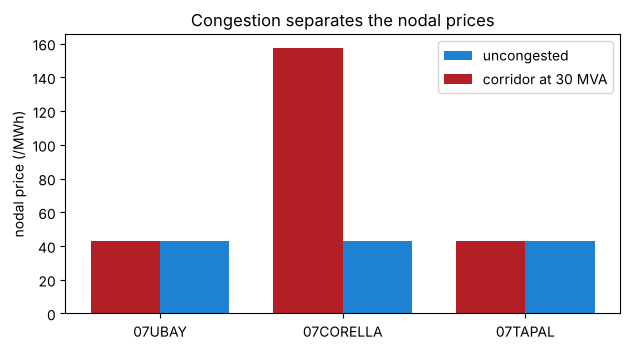

saved figures/06_nodal_prices.png


In [5]:
fig, ax = plt.subplots(figsize=(6.4, 3.6))
b = ["07UBAY", "07CORELLA", "07TAPAL"]
ax.bar(b, [base.buses_t.marginal_price.iloc[0][x] for x in b],
       width=0.38, align="edge", label="uncongested", color="#1E81D4")
ax.bar(b, [price[x] for x in b], width=-0.38, align="edge",
       label="corridor at 30 MVA", color="#B41E25")
ax.set_ylabel("nodal price (/MWh)")
ax.set_title("Congestion separates the nodal prices")
ax.legend()
fig.tight_layout(); fig.savefig(FIG / "06_nodal_prices.png", dpi=130); plt.show()
print("saved figures/06_nodal_prices.png")

### 6.5 N-1 security screen

A secure system survives the loss of **any one line**. We drop each line in turn,
re-optimise, and record the worst line loading, whether diesel had to start, and
the cost. If any case cannot be solved, that outage would **shed load** - a
security violation. We run the screen twice: with a strong corridor and with the
congested one.

In [6]:
def n1_screen(corridor_mva=None):
    rows = []
    all_lines = peak_network(corridor_mva).lines.index
    for out in [None] + list(all_lines):
        n = peak_network(corridor_mva, drop_line=out)
        status, _ = n.optimize(**OPT)
        if status != "ok" or n.generators_t.p.empty:
            rows.append({"outage": out or "intact", "feasible": "NO (load shed)",
                         "worst line %": np.nan, "diesel MW": np.nan, "cost": np.nan})
            continue
        load = loading_pct(n)
        disp = n.generators_t.p.iloc[0].groupby(n.generators.carrier).sum()
        rows.append({"outage": out or "intact", "feasible": "yes",
                     "worst line %": load.max(),
                     "diesel MW": round(disp.get("Diesel", 0), 1),
                     "cost": round(float(n.objective))})
    return pd.DataFrame(rows).set_index("outage")

print("Real ratings (138 / 69 MVA) - N-1 secure:")
print(n1_screen(None).to_string())
print("\nDerated corridor (30 MVA each) - N-1 stressed:")
print(n1_screen(30.0).to_string())

Real ratings (138 / 69 MVA) - N-1 secure:


                     feasible  worst line %  diesel MW  cost
outage                                                      
intact                    yes          23.9        0.0  3107
69_07UBAY_07TAPAL         yes          23.9        0.0  3107
138_07UBAY_07CORELLA      yes          64.8        0.0  3107
69_07UBAY_07CORELLA       yes          32.4        0.0  3107

Derated corridor (30 MVA each) - N-1 stressed:


                     feasible  worst line %  diesel MW  cost
outage                                                      
intact                    yes         100.0        4.0  3565
69_07UBAY_07TAPAL         yes         100.0        4.0  3565
138_07UBAY_07CORELLA      yes         100.0       14.7  4795
69_07UBAY_07CORELLA       yes         100.0       14.7  4795


**Read the screen.** At the real ratings every outage is feasible and the worst
remaining line stays around 65 % - the island is **N-1 secure**. With the derated
corridor, losing the 138 kV line pins the surviving 69 kV line at **100 %** and
forces ~15 MW of diesel: the system still stands, but only by burning expensive
fuel. That gap between "feasible" and "cheap" is exactly what a planner invests
to close - the subject of Chapter 7.

## Summary of Chapter 6

- A **congested** line stops cheap power reaching a load; the load bus then pays
  its local plant's cost, so **nodal prices separate** (Corella 157.52 vs Ubay
  42.73).
- Parallel lines share current by **impedance, not rating** (loop flow), so the
  138 kV line saturates while the 69 kV line is half empty.
- An **N-1 screen** re-optimises for the loss of each line. Bohol is secure at
  full ratings; derated, a single outage leaves it leaning hard on diesel.
- Next chapter we let PyPSA **build** new capacity - and finally make a CO2 cap
  bite - by optimising investment, not just operation.